In [18]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd
import numpy as np
from matplotlib import pyplot
from statsmodels.tsa.seasonal import seasonal_decompose

In [4]:
df = pd.read_csv('us-airlines-monthly-aircraft-miles-flown.csv', header=0 , parse_dates=[0])

In [5]:
df.head()

,Month,MilesMM
0,1963-01-01,6827
1,1963-02-01,6178
2,1963-03-01,7084
3,1963-04-01,8162
4,1963-05-01,8462


In [6]:
df.index = df['Month']

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

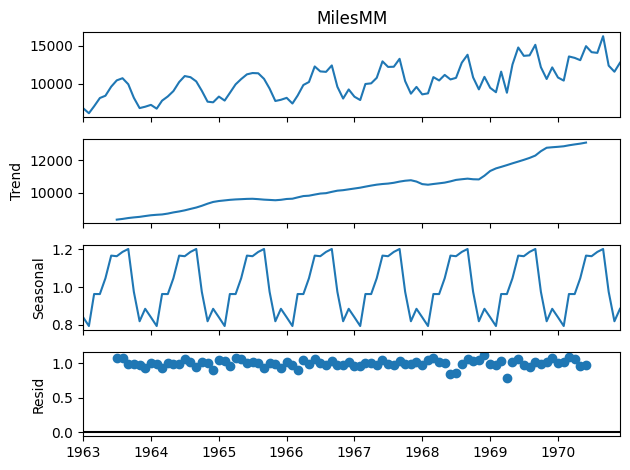

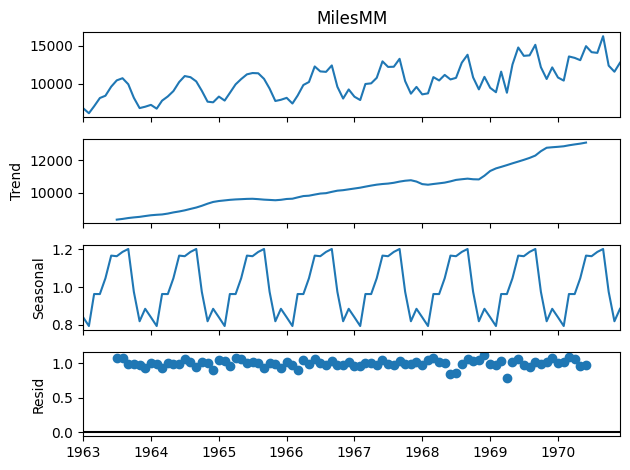

In [8]:
result_a = seasonal_decompose(df['MilesMM'], model='multiplicative')
result_a.plot()

In [9]:
model = SARIMAX(df['MilesMM'], order=(5,1,3), seasonal_order=(1,1,1,12))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [10]:
model_fit = model.fit()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [11]:
residuals = model_fit.resid

<Axes: xlabel='Month'>

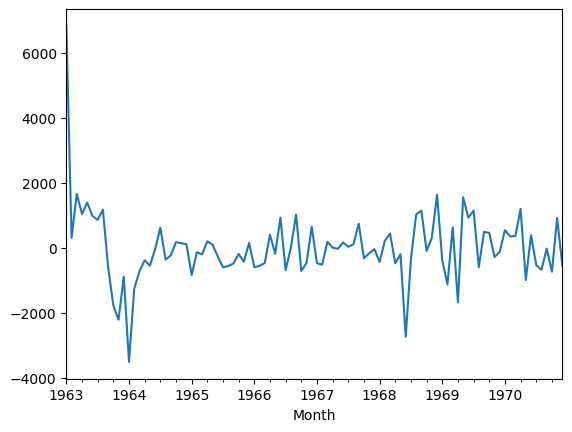

In [12]:
residuals.plot()

In [13]:
output = model_fit.forecast()

In [14]:
output

,0
1971-01-01,11475.446031


In [15]:
model_fit.forecast(12)

,predicted_mean
1971-01-01,11475.446031
1971-02-01,11153.441319
1971-03-01,13669.060309
1971-04-01,12646.852005
1971-05-01,14338.954056
1971-06-01,15785.890688
1971-07-01,14978.721549
1971-08-01,15362.173443
1971-09-01,16962.439625
1971-10-01,13681.970006


In [16]:
yhat = model_fit.predict()

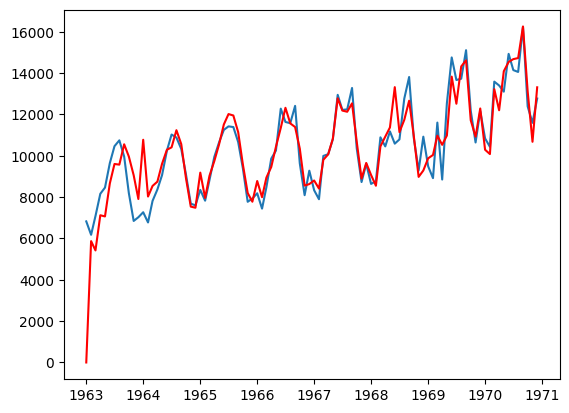

In [19]:
pyplot.plot(df['MilesMM'])
pyplot.plot(yhat, color='red')